In [103]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [104]:
hours = np.array([2, 4, 3, 10, 7])
score = np.array([80, 89, 56, 100, 94])

X = hours
y = score

In [105]:
X = hours.reshape(-1, 1)

In [106]:
y

array([ 80,  89,  56, 100,  94])

In [107]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

In [108]:
poly = PolynomialFeatures(degree=2)

In [109]:
poly

,degree,2
,interaction_only,False
,include_bias,True
,order,'C'


In [110]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.fit_transform(X_test)

In [111]:
X_train

array([[10],
       [ 7],
       [ 2],
       [ 3]])

In [112]:
X_train_poly

array([[  1.,  10., 100.],
       [  1.,   7.,  49.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.]])

In [113]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [114]:
model.intercept_

np.float64(65.07682458386688)

In [115]:
model.coef_

array([0.        , 1.53201024, 0.22215109])

In [116]:
y_pred = model.predict(X_test_poly)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred.round(2)
})

print(results)

   Actual  Predicted
0      89      74.76


In [117]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MSE: 202.79802151285134
RMSE: 14.240717029449442
R2 Score: nan


c:\Users\konta\anaconda3\envs\ds\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


In [119]:
import matplotlib.pyplot as plt

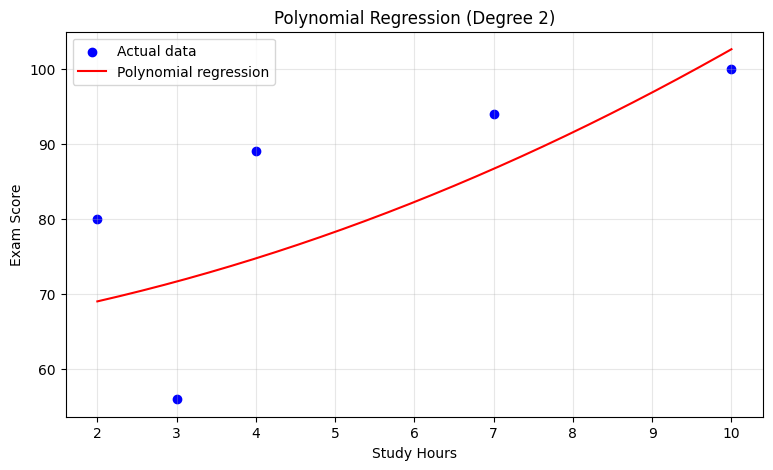

In [120]:
# Generate points for a smooth curve
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

# Transform them using the same polynomial transformer
X_curve_poly = poly.transform(X_curve)

# Predict
y_curve = model.predict(X_curve_poly)

# Plot
plt.figure(figsize=(9, 5))

plt.scatter(X, y, color="blue", label="Actual data")
plt.plot(X_curve, y_curve, color="red", label="Polynomial regression")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Polynomial Regression (Degree 2)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [121]:
degrees = [1, 2, 3, 4]

for degree in degrees:

    # Feature transformation
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Model training
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Prediction
    y_pred = model.predict(X_test_poly)

    # Evaluation
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"\nDegree: {degree}")
    print(f"Number of features: {X_train_poly.shape[1]}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.4f}")


Degree: 1
Number of features: 2
RMSE: 12.76
R2: nan

Degree: 2
Number of features: 3
RMSE: 14.24
R2: nan

Degree: 3
Number of features: 4
RMSE: 37.77
R2: nan

Degree: 4
Number of features: 5
RMSE: 45.10
R2: nan


c:\Users\konta\anaconda3\envs\ds\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\konta\anaconda3\envs\ds\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\konta\anaconda3\envs\ds\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\konta\anaconda3\envs\ds\Lib\site-packages\sklearn\metrics\_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


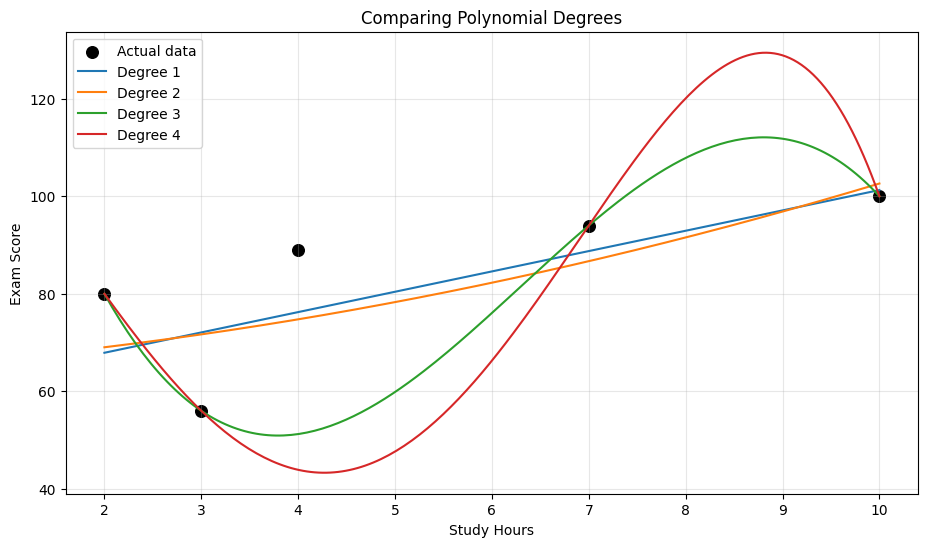

In [122]:
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plt.figure(figsize=(11, 6))

plt.scatter(X, y, color="black", s=70, label="Actual data")

for degree in [1, 2, 3, 4]:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_curve_poly = poly.transform(X_curve)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_curve = model.predict(X_curve_poly)

    plt.plot(X_curve, y_curve, label=f"Degree {degree}")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Comparing Polynomial Degrees")
plt.legend()
plt.grid(alpha=0.3)
plt.show()